**Role of AI:**
Ray Verify’s AI component will classify a chest X-ray as patient-acquired or synthetic using patterns learned from labeled examples. It takes a preprocessed image as input and produces scores for the two origin classes; a separate threshold rule displays Uncertain when the highest score is too low. The prediction supports a research data curator, who makes the final inclusion decision.


**Candidate models and first choice:**
My 2 candidates include: Pretrained ResNet-18 with transfer learning, 
                         DenseNet121,
I will explore pretrained ResNet-18 first, initially freezing its feature-extraction layers and training a new two-class output layer. This fits the image-classification task. My current code prepares 256 × 256 grayscale images; the model-input pipeline will adapt these to the pretrained model’s channel and normalization requirements. Changed it to three channels of 224 * 224.
Parts of the workflow that are not AI:
Preprocessing and data cleaning, Data loading and data splitting, Duplicate checking, Brightness Augmentation, Withholding threshold and Metadata. 



Data Loading 

In [1]:
import numpy as np 
import pandas as pd
from pathlib import Path
from PIL import Image, ImageOps
import json
import torch

from torch import nn
image_folder_synthetic = Path(r"/home/vsarasani/Ray-Verify-/Data/all_synthetic_images")
print("Folder found:", image_folder_synthetic.is_dir())

Folder found: True


In [2]:
images = []
valid_paths = []
failed_files = []

for path in image_folder_synthetic.rglob("*"):
    if path.is_file() and path.suffix.lower() in {
        ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}:
        try:
            with Image.open(path) as img:
                images.append(img.copy())
            valid_paths.append(path)

        except OSError:
            failed_files.append(path)
            print("Cannot read:", path.name)

print("Images loaded:", len(images))
print("Unreadable files:", len(failed_files))

Images loaded: 6289
Unreadable files: 0


In [3]:
image_folder_patient = Path(r"/home/vsarasani/Ray-Verify-/Data/patient acquired")
print("Folder found:", image_folder_patient.is_dir())

Folder found: True


In [4]:
images = []
for path in image_folder_patient.rglob("*"):
    if path.is_file() and path.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}:
        with Image.open(path) as img:
            images.append(img.copy())

print("Images loaded:", len(images))

Images loaded: 6319


Inspecting patient acquired data

In [5]:
patient_folder = Path("/home/vsarasani/Ray-Verify-/Data/patient acquired")

if not patient_folder.is_dir():
    raise FileNotFoundError(f"Folder not found: {patient_folder}")

patient_records = []
failed_files = []

for path in sorted(patient_folder.rglob("*")):
    if path.is_file() and path.suffix.lower() in { ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}:
        try:
            with Image.open(path) as img:
                pixels = np.asarray(img)

                patient_records.append({
                    "image_number": len(patient_records) + 1,
                    "filename": path.name,
                    "width": img.width,
                    "height": img.height,
                    "channels": len(img.getbands()),
                    "mode": img.mode,
                    "pixel_data_type": str(pixels.dtype),
                    "pixel_values": pixels.size
                })
        except OSError as error:
            failed_files.append(str(path))
            print("Cannot read:", path.name)

patient_image_info = pd.DataFrame(patient_records)

print("Patient-acquired images read:", len(patient_image_info))
print("Failed files:", len(failed_files))
print("Features per image = width × height × channels")

display(patient_image_info.head())
display(patient_image_info.dtypes)

Patient-acquired images read: 6319
Failed files: 0
Features per image = width × height × channels


,image_number,filename,width,height,channels,mode,pixel_data_type,pixel_values
0,1,0005e8e3701dfb1dd93d53e2ff537b6e-checkpoint.png,256,256,1,L,uint8,65536
1,2,0006e0a85696f6bb578e84fafa9a5607.png,256,256,1,L,uint8,65536
2,3,0007d316f756b3fa0baea2ff514ce945.png,256,256,1,L,uint8,65536
3,4,0021df30f3fddef551eb3df4354b1d06.png,256,256,1,L,uint8,65536
4,5,002a34c58c5b758217ed1f584ccbcfe9.png,256,256,1,L,uint8,65536


image_number        int64
filename           object
width               int64
height              int64
channels            int64
mode               object
pixel_data_type    object
pixel_values        int64
dtype: object

Inspecting Synthetic ai data

In [6]:
synthetic_folder = Path("/home/vsarasani/Ray-Verify-/Data/all_synthetic_images")

if not synthetic_folder.is_dir():
    raise FileNotFoundError(f"Folder not found: {synthetic_folder}")

synthetic_records = []
failed_files = []

for path in sorted(synthetic_folder.rglob("*")):
    if path.is_file() and path.suffix.lower() in {
        ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff" }:
        try:
            with Image.open(path) as img:
                pixels = np.asarray(img)

                synthetic_records.append({
                    "image_number": len(synthetic_records) + 1,
                    "filename": path.name,
                    "width": img.width,
                    "height": img.height,
                    "channels": len(img.getbands()),
                    "mode": img.mode,
                    "pixel_data_type": str(pixels.dtype),
                    "pixel_values": pixels.size
                })
        except OSError as error:
            failed_files.append(str(path))
            print("Cannot read:", path.name)

synthetic_image_info = pd.DataFrame(synthetic_records)

print("Synthetic-acquired images read:", len(synthetic_image_info))
print("Failed files:", len(failed_files))
print("Features per image = width × height × channels")

display(synthetic_image_info.head())
display(synthetic_image_info.dtypes)

Synthetic-acquired images read: 6289
Failed files: 0
Features per image = width × height × channels


,image_number,filename,width,height,channels,mode,pixel_data_type,pixel_values
0,1,00001_COVID19(10)-checkpoint-checkpoint.jpg,1038,1031,3,RGB,uint8,3210534
1,2,00001_COVID19(10)-checkpoint-checkpoint.png,256,256,1,L,uint8,65536
2,3,00002_person107_virus_197-checkpoint.png,256,256,1,L,uint8,65536
3,4,00003_person10_bacteria_43-checkpoint.png,256,256,1,L,uint8,65536
4,5,00004_COVID19(0).png,256,256,1,L,uint8,65536


image_number        int64
filename           object
width               int64
height              int64
channels            int64
mode               object
pixel_data_type    object
pixel_values        int64
dtype: object

PREPROCESS AND DATA CLEANING

Transforming JPEG files in synthetic data to PNG

In [7]:
image_folder = Path("Data/all_synthetic_images")

print("Folder found:", image_folder.is_dir())

Folder found: True


Converting JPG to PNG

In [8]:
image_folder = Path("Data/all_synthetic_images")  

count = 0

for path in image_folder.iterdir():
    if path.suffix.lower() in {".jpg", ".jpeg"}:
        png_path = path.with_suffix(".png")

        if png_path.exists():
            print("Skipped — PNG already exists:", path.name)
            continue

        with Image.open(path) as img:
            img.save(png_path, format="PNG")

        path.unlink()  
        count += 1

print("JPEG files replaced with PNG:", count)

JPEG files replaced with PNG: 0


2110 files were in jpg form, converted all and run the cell again to make sure none are left. That is the reason it is showing 0 files converted.

Converting the Synthetic ai images to grayscale and with same number of pixels as patient- acquired. 

In [9]:
image_folder = Path("/home/vsarasani/Ray-Verify-/Data/all_synthetic_images")

count = 0

for path in image_folder.iterdir():
    if path.is_file() and path.suffix.lower() == ".png":
        with Image.open(path) as img:
            img = img.convert("L")  

            img = ImageOps.pad(
                img,
                (256, 256),
                method=Image.Resampling.LANCZOS,
                color=0)

        img.save(path, format="PNG")
        count += 1

print("Images resized:", count)
print("Size: 256 × 256")
print("Channels: 1 (grayscale)")
print("Pixel values per image:", 256 * 256)

Images resized: 6287
Size: 256 × 256
Channels: 1 (grayscale)
Pixel values per image: 65536


All images are now in grayscale,same dimensions, same format and same number of pixels.

Deleting duplicate images

In [10]:
import hashlib

image_folder = Path("/home/vsarasani/Ray-Verify-/Data/all_synthetic_images")

seen = {}
duplicates = []
failed_files = []

for path in sorted(image_folder.rglob("*")):
    if not path.is_file() or path.suffix.lower() not in {".png", ".jpg", ".jpeg"}:
        continue

    try:
        with Image.open(path) as img:
            img = img.convert("RGB")
            image_hash = hashlib.sha256(
                str(img.size).encode() + img.tobytes()).hexdigest()

        if image_hash in seen:
            duplicates.append((seen[image_hash], path))
        else:
            seen[image_hash] = path

    except OSError:
        failed_files.append(path)
        print("Cannot read:", path.name)

print("Extra duplicate copies:", len(duplicates))
print("Unreadable files:", len(failed_files))

for original, duplicate in duplicates:
    print("\nFirst copy:", original)
    print("Duplicate: ", duplicate)

Extra duplicate copies: 0
Unreadable files: 0


In [11]:
deleted = 0

for original, duplicate in duplicates:
    if original.exists() and duplicate.exists() and original != duplicate:
        duplicate.unlink()
        print("Deleted:", duplicate.name)
        deleted += 1

print("Duplicate copies deleted:", deleted)

Duplicate copies deleted: 0


In [12]:
image_folder = Path("/home/vsarasani/Ray-Verify-/Data/patient acquired")

seen = {}
duplicates = []
failed_files = []

for path in sorted(image_folder.rglob("*")):
    if not path.is_file() or path.suffix.lower() not in {".png", ".jpg", ".jpeg"}:
        continue

    try:
        with Image.open(path) as img:
            img = img.convert("RGB")
            image_hash = hashlib.sha256(
                str(img.size).encode() + img.tobytes()
            ).hexdigest()

        if image_hash in seen:
            duplicates.append((seen[image_hash], path))
        else:
            seen[image_hash] = path

    except OSError:
        failed_files.append(path)
        print("Cannot read:", path.name)

print("Extra duplicate copies:", len(duplicates))
print("Unreadable files:", len(failed_files))

for original, duplicate in duplicates:
    print("\nFirst copy:", original)
    print("Duplicate: ", duplicate)

Extra duplicate copies: 0
Unreadable files: 0


**Filling or Dropping** is not necessary

Deleted all duplicate values. 

Creating a .csv metadata file

In [13]:
base = Path("/home/vsarasani/Ray-Verify-/Data")

sources = [
    (
        base / "patient acquired",
        "patient-acquired",
        "https://www.kaggle.com/datasets/xhlulu/vinbigdata-chest-xray-resized-png-256x256"
    ),
    (
        base / "all_synthetic_images",
        "synthetic",
        "https://www.kaggle.com/code/farihabintasadeque/synthetic-chestxrays/input?select=train"
    )
]

rows = []

for folder, label, source_url in sources:
    if not folder.is_dir():
        raise FileNotFoundError(f"Folder not found: {folder}")

    for path in sorted(folder.rglob("*")):
        if not path.is_file() or path.suffix.lower() not in {
            ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}:
            continue

        processing_state = "unknown"
        quality_status = "unreadable"

        try:
            with Image.open(path) as img:
                img.load()
                processing_state = (f"{img.format}; {img.width}x{img.height}; mode={img.mode}")
                quality_status = "readable; duplicates not checked here"
        except OSError:
            pass

        rows.append({
            "image_path": str(path.relative_to(base)),
            "source_url": source_url,
            "download_date": "10-03-2026",
            "origin_label": label,
            "label_status": "provisional",
            "provenance_evidence": "unknown",
            "processing_state": processing_state,
            "quality_status": quality_status,})

metadata = pd.DataFrame(rows)

output = base / "image_metadata.csv"
metadata.to_csv(output, index=False)

print("Images recorded:", len(metadata))
print("Saved to:", output)
display(metadata.head())

Images recorded: 12608
Saved to: /home/vsarasani/Ray-Verify-/Data/image_metadata.csv


,image_path,source_url,download_date,origin_label,label_status,provenance_evidence,processing_state,quality_status
0,patient acquired/.ipynb_checkpoints/0005e8e370...,https://www.kaggle.com/datasets/xhlulu/vinbigd...,10-03-2026,patient-acquired,provisional,unknown,PNG; 256x256; mode=L,readable; duplicates not checked here
1,patient acquired/0006e0a85696f6bb578e84fafa9a5...,https://www.kaggle.com/datasets/xhlulu/vinbigd...,10-03-2026,patient-acquired,provisional,unknown,PNG; 256x256; mode=L,readable; duplicates not checked here
2,patient acquired/0007d316f756b3fa0baea2ff514ce...,https://www.kaggle.com/datasets/xhlulu/vinbigd...,10-03-2026,patient-acquired,provisional,unknown,PNG; 256x256; mode=L,readable; duplicates not checked here
3,patient acquired/0021df30f3fddef551eb3df4354b1...,https://www.kaggle.com/datasets/xhlulu/vinbigd...,10-03-2026,patient-acquired,provisional,unknown,PNG; 256x256; mode=L,readable; duplicates not checked here
4,patient acquired/002a34c58c5b758217ed1f584ccbc...,https://www.kaggle.com/datasets/xhlulu/vinbigd...,10-03-2026,patient-acquired,provisional,unknown,PNG; 256x256; mode=L,readable; duplicates not checked here


Creating .gitignore file 

In [14]:
from pathlib import Path

gitignore = Path("/home/vsarasani/Ray-Verify-/.gitignore")

rules = gitignore.read_text().splitlines() if gitignore.exists() else []
rules = [rule for rule in rules if rule.strip()]

rules = ["Data/" if rule.strip() == "data/" else rule for rule in rules]

if "Data/" not in rules:
    rules.append("Data/")

rules = list(dict.fromkeys(rules))

gitignore.write_text("\n".join(rules) + "\n")

print("File:", gitignore)
print(gitignore.read_text())

File: /home/vsarasani/Ray-Verify-/.gitignore
Data/



Splitting testing data

**Data separation:** The test set remains separate; five-fold validation uses only the development set.

In [15]:
from sklearn.model_selection import train_test_split

patient_files = sorted(
    Path("/home/vsarasani/Ray-Verify-/Data/patient acquired").glob("*.png"))

synthetic_files = sorted(
    Path("/home/vsarasani/Ray-Verify-/Data/all_synthetic_images").glob("*.png"))

X = patient_files + synthetic_files
y = [0] * len(patient_files) + [1] * len(synthetic_files)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42)

Training images will receive random brightness augmentation and ResNet-18 preprocessing when loaded. Validation and test images will receive the same preprocessing without random augmentation.

Exact files used for modelling 

**Confirm labels and balance**

In [16]:
import numpy as np
import pandas as pd

print("Label 0: patient-acquired")
print("Label 1: synthetic")

split_summary = pd.DataFrame({
    "Development": pd.Series(y_train).value_counts(),
    "Test": pd.Series(y_test).value_counts()
}).fillna(0).astype(int)

split_summary.index.name = "Label"
display(split_summary)

print("Total model inputs:", len(X_train) + len(X_test))
print("Development images:", len(X_train))
print("Test images:", len(X_test))

assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)
assert set(y_train) == {0, 1}
assert set(y_test) == {0, 1}

Label 0: patient-acquired
Label 1: synthetic


,Development,Test
Label,,
0,5054,1264
1,5030,1257


Total model inputs: 12605
Development images: 10084
Test images: 2521


The two classes are nearly balanced, so no oversampling or undersampling is needed based on these counts.

Checking for duplicates across both splits

Creating input_audit.csv records each image’s path, split, label, pixel hash, and any detected issues, providing evidence of the input and exact-duplicate checks performed before training.

In [17]:
import hashlib

records = []

for split, paths, labels in [
    ("development", X_train, y_train),
    ("test", X_test, y_test)
]:
    for path, label in zip(paths, labels):
        path = Path(path)
        issue = ""
        pixel_hash = None

        try:
            with Image.open(path) as img:
                img.load()

                if img.size != (256, 256) or img.mode != "L":
                    issue = f"Unexpected input: {img.size}, mode={img.mode}"

                gray = img.convert("L")
                pixel_hash = hashlib.sha256(
                    str(gray.size).encode() + gray.tobytes()
                ).hexdigest()

        except (OSError, ValueError) as error:
            issue = f"Unreadable: {error}"

        records.append({
            "path": str(path.resolve()),
            "split": split,
            "label": label,
            "pixel_hash": pixel_hash,
            "issue": issue
        })

audit = pd.DataFrame(records)

problems = audit[audit["issue"] != ""]
readable = audit.dropna(subset=["pixel_hash"])
duplicates = readable[
    readable.duplicated("pixel_hash", keep=False)
]

print("Invalid images:", len(problems))
print("Images involved in exact duplicates:", len(duplicates))

display(problems)
display(duplicates)

audit.to_csv("input_audit.csv", index=False)

if not problems.empty or not duplicates.empty:
    raise ValueError(
        "Review input_audit.csv and resolve the listed issues before continuing."
    )

Invalid images: 0
Images involved in exact duplicates: 0


,path,split,label,pixel_hash,issue


,path,split,label,pixel_hash,issue


Adding ResNet-18 input preparation

**Environment setup:** I encountered a PyTorch import error related to the dill package. After reinstalling it, the missing extend function became available and input preprocessing ran successfully. dill is useful here because your installed PyTorch version uses it internally. Fixing its installation allowed PyTorch to import successfully so you could continue preparing images for ResNet-18. 

In [18]:
import dill

print("Location:", getattr(dill, "__file__", None))
print("Version:", getattr(dill, "__version__", "Unknown"))
print("Has extend:", hasattr(dill, "extend"))

Location: /home/vsarasani/.local/lib/python3.10/site-packages/dill/__init__.py
Version: 0.4.1
Has extend: True


In [19]:
%pip install --upgrade --force-reinstall --no-cache-dir dill

Defaulting to user installation because normal site-packages is not writeable
  Attempting uninstall: dill
    Found existing installation: dill 0.4.1
    Uninstalling dill-0.4.1:
      Successfully uninstalled dill-0.4.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.3.0 requires dill<0.4.1,>=0.3.0, but you have dill 0.4.1 which is incompatible.

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


**Changed:** Synthetic images were previously converted to PNG and standardized to 256 × 256 grayscale. ResNet preprocessing now transforms images in memory to three-channel 224 × 224 tensors.

Prepared three-channel, 224 × 224 images and normalized them and Adding brightness augmentation only to training images

**Confirm input shape and type**

In [20]:
from torchvision import transforms
from torchvision.models import ResNet18_Weights

weights = ResNet18_Weights.DEFAULT

eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    weights.transforms()])

train_transform = transforms.Compose([
    transforms.ColorJitter(brightness=(0.95, 1.05)),
    eval_transform])

def load_model_input(path, training=False):
    with Image.open(path) as img:
        img = img.convert("L")
        transform = train_transform if training else eval_transform
        return transform(img)

sample = load_model_input(X_train[0], training=False)

print("ResNet-18 input shape:", tuple(sample.shape))
print("Data type:", sample.dtype)
print("All values finite:", bool(sample.isfinite().all()))

ResNet-18 input shape: (3, 224, 224)
Data type: torch.float32
All values finite: True


Adding a dataset loader

It loads images in batches instead of storing every processed image in memory.

In [21]:
import torch
from torch.utils.data import Dataset, DataLoader

class XrayDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = list(paths)
        self.labels = list(labels)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as img:
            image = self.transform(img.convert("L"))

        label = torch.tensor(
            self.labels[index],
            dtype=torch.long )

        return image, label

Dividing development data into five training/validation folds.

In [22]:

from sklearn.model_selection import StratifiedKFold

X_pool = np.asarray(X_train, dtype=object)
y_pool = np.asarray(y_train, dtype=np.int64)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42)

folds = list(cv.split(X_pool, y_pool))

for fold, (train_idx, val_idx) in enumerate(folds, start=1):
    print(
        f"Fold {fold}: "
        f"{len(train_idx)} training images, "
        f"{len(val_idx)} validation images")

Fold 1: 8067 training images, 2017 validation images
Fold 2: 8067 training images, 2017 validation images
Fold 3: 8067 training images, 2017 validation images
Fold 4: 8067 training images, 2017 validation images
Fold 5: 8068 training images, 2016 validation images


Loading images in batches of 16 instead of preparing thousands of image arrays at once.

In [23]:
def make_fold_loaders(train_idx, val_idx, batch_size=16):
    train_dataset = XrayDataset(
        X_pool[train_idx],
        y_pool[train_idx],
        transform=train_transform)

    val_dataset = XrayDataset(
        X_pool[val_idx],
        y_pool[val_idx],
        transform=eval_transform)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0)

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0 )

    return train_loader, val_loader

Check a training and validation batch from every fold

In [24]:
for fold, (train_idx, val_idx) in enumerate(folds, start=1):
    train_loader, val_loader = make_fold_loaders(
        train_idx, val_idx
    )

    for name, loader in [
        ("Training", train_loader),
        ("Validation", val_loader) ]:
        batch_images, batch_labels = next(iter(loader))

        assert batch_images.shape[1:] == (3, 224, 224)
        assert batch_images.dtype == torch.float32
        assert torch.isfinite(batch_images).all().item()
        assert batch_labels.dtype == torch.long
        assert set(batch_labels.tolist()).issubset({0, 1})

        print(
            f"Fold {fold} | {name} | "
            f"Images: {tuple(batch_images.shape)} | "
            f"Labels: {tuple(batch_labels.shape)}" )

Fold 1 | Training | Images: (16, 3, 224, 224) | Labels: (16,)
Fold 1 | Validation | Images: (16, 3, 224, 224) | Labels: (16,)
Fold 2 | Training | Images: (16, 3, 224, 224) | Labels: (16,)
Fold 2 | Validation | Images: (16, 3, 224, 224) | Labels: (16,)
Fold 3 | Training | Images: (16, 3, 224, 224) | Labels: (16,)
Fold 3 | Validation | Images: (16, 3, 224, 224) | Labels: (16,)
Fold 4 | Training | Images: (16, 3, 224, 224) | Labels: (16,)
Fold 4 | Validation | Images: (16, 3, 224, 224) | Labels: (16,)
Fold 5 | Training | Images: (16, 3, 224, 224) | Labels: (16,)
Fold 5 | Validation | Images: (16, 3, 224, 224) | Labels: (16,)


Checks one training batch and one validation batch from each of the five folds.
It confirms that each batch contains 16 images of shape (3, 224, 224), with valid numerical values and labels of 0 or 1.

With 16 images per batch, folds 1–4 each have 505 training batches and 127 validation batches, while fold 5 has 505 training batches and 126 validation batches; the final batch may contain fewer than 16 images.

Implementing a model

Defining the training settings, including the number of epochs, batch size, learning rate, and random seed. Saves the configuration

In [25]:
import json
import random
import platform
from datetime import datetime
import torchvision
from torch import nn
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import ( accuracy_score,
                             balanced_accuracy_score,
                             classification_report,
                             confusion_matrix)

SEED = 42
EPOCHS = 10
BATCH_SIZE = 16
LEARNING_RATE = 0.001

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed(SEED)

run_dir = Path(
    f"runs/resnet18_10epochs_{datetime.now():%Y%m%d_%H%M%S_%f}"
)
run_dir.mkdir(parents=True, exist_ok=False)

audit_bytes = Path("input_audit.csv").read_bytes()
(run_dir / "input_audit.csv").write_bytes(audit_bytes)
validation_fold = np.zeros(len(X_pool), dtype=int)

for fold_number, (_, val_idx) in enumerate(folds, start=1):
    validation_fold[val_idx] = fold_number

pd.DataFrame({
    "path": [str(p) for p in X_pool],
    "label": y_pool,
    "validation_fold": validation_fold}).to_csv(run_dir / "development_manifest.csv", index=False)

pd.DataFrame({
    "path": [str(p) for p in X_test],
    "label": y_test}).to_csv(run_dir / "test_manifest.csv", index=False)

config = {
    "model": "ResNet-18",
    "pretrained_weights": "IMAGENET1K_V1",
    "python_version": platform.python_version(),
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "dataset_snapshot_sha256": hashlib.sha256(audit_bytes).hexdigest(),
    "label_status": "provisional",
    "labels": {"0": "patient-acquired", "1": "synthetic"},
    "development_images": len(X_pool),
    "test_images": len(X_test),
    "split": "Existing 80/20 stratified split; 5 folds within development",
    "epochs_per_model": EPOCHS,
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "loss": "CrossEntropyLoss",
    "trainable_layer": "fc",
    "backbone": "Frozen, including BatchNorm running statistics",
    "training_transform": str(train_transform),
    "evaluation_transform": str(eval_transform),
    "seed": SEED,
    "device": str(device),
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available() else None),
    "checkpoint_rule": "Use epoch 10; no best-epoch selection",
    "prediction_rule": "Largest of two output scores",
    "uncertainty_threshold": "Not yet implemented"}

(run_dir / "configuration.json").write_text(
    json.dumps(config, indent=2))

print("Device:", device)
print("Configuration saved:", run_dir)

Device: cuda
Configuration saved: runs/resnet18_10epochs_20261026_131749_195740


It defined settings used later: 10 epochs, batch size 16, learning rate, and random seed.
Selects the GPU.
Creates the folder for saving your model and results.
Records the configuration before tuning

Defining model

In [26]:
def build_model():
    model = resnet18(
        weights=ResNet18_Weights.IMAGENET1K_V1)

    for parameter in model.parameters():
        parameter.requires_grad = False

    model.fc = nn.Linear(model.fc.in_features, 2)

    return model.to(device)

Checking whether ResNet-18 can process our prepared images without errors

In [27]:
set_seed(SEED)
check_model = build_model()

check_dataset = XrayDataset(
    X_pool[:BATCH_SIZE],
    y_pool[:BATCH_SIZE],
    transform=eval_transform)

check_loader = DataLoader(
    check_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0)

images, labels = next(iter(check_loader))

check_model.eval()

with torch.no_grad():
    outputs = check_model(images.to(device))

assert outputs.shape == (len(images), 2)
assert torch.isfinite(outputs).all().item()

print("Input shape:", tuple(images.shape))
print("Output shape:", tuple(outputs.shape))

del check_model, outputs

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Input shape: (16, 3, 224, 224)
Output shape: (16, 2)


Set up the metrics and record this run

In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix)

EPOCHS = 10
LEARNING_RATE = 0.001

criterion = nn.CrossEntropyLoss()

all_history = []
fold_results = []

oof_predictions = np.full(len(X_pool), -1, dtype=int)
oof_scores = np.full(len(X_pool), np.nan)
oof_fold = np.zeros(len(X_pool), dtype=int)

config.update({
    "evaluation": "All five existing development folds",
    "epochs_per_fold": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "trainable_layer": "fc only",
    "checkpoint_rule": "Use epoch 10",
    "uncertainty_threshold": "Not yet selected"})

(run_dir / "configuration.json").write_text(
    json.dumps(config, indent=2))

1615

Training and evaluation for all 5 folds and 10 epochs each fold 

In [32]:
for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):

    print(f"\nStarting fold {fold_number}/5", flush=True)

    set_seed(SEED)
    model = build_model()

    optimizer = torch.optim.Adam(
        model.fc.parameters(),
        lr=LEARNING_RATE)

    train_loader, val_loader = make_fold_loaders(
        train_idx,
        val_idx,
        batch_size=BATCH_SIZE)

    for epoch in range(1, EPOCHS + 1):

        model.eval()
        model.fc.train()

        training_loss = 0.0
        training_count = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            if not torch.isfinite(loss).item():
                raise RuntimeError("Training loss is not finite.")

            loss.backward()
            optimizer.step()

            training_loss += loss.item() * labels.size(0)
            training_count += labels.size(0)

        training_loss /= training_count


        model.eval()

        actual_labels = []
        predicted_labels = []
        model_scores = []
        validation_loss = 0.0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                probabilities = torch.softmax(outputs, dim=1)
                scores, predictions = probabilities.max(dim=1)

                validation_loss += loss.item() * labels.size(0)

                actual_labels.extend(labels.cpu().tolist())
                predicted_labels.extend(predictions.cpu().tolist())
                model_scores.extend(scores.cpu().tolist())

        validation_loss /= len(val_loader.dataset)

        accuracy = accuracy_score(actual_labels, predicted_labels)
        precision = precision_score(actual_labels, predicted_labels, zero_division=0 )
        recall = recall_score(actual_labels, predicted_labels, zero_division=0)
        f1 = f1_score(actual_labels, predicted_labels, zero_division=0)

        all_history.append({
            "fold": fold_number,
            "epoch": epoch,
            "training_loss": training_loss,
            "validation_loss": validation_loss,
            "accuracy": accuracy,
            "precision": precision,
            "recall": recall,
            "f1": f1})

    
        pd.DataFrame(all_history).to_csv(
            run_dir / "five_fold_training_history.csv",
            index=False )

        print(
            f"Fold {fold_number}/5 | Epoch {epoch}/{EPOCHS} | "
            f"Train loss: {training_loss:.4f} | "
            f"Val loss: {validation_loss:.4f} | "
            f"Accuracy: {accuracy:.4f} | "
            f"Precision: {precision:.4f} | "
            f"Recall: {recall:.4f} | "
            f"F1: {f1:.4f}",
            flush=True )


    fold_results.append({
        "fold": fold_number,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1})

    oof_predictions[val_idx] = predicted_labels
    oof_scores[val_idx] = model_scores
    oof_fold[val_idx] = fold_number

    pd.DataFrame({
        "path": [str(p) for p in X_pool[val_idx]],
        "true_label": actual_labels,
        "predicted_label": predicted_labels,
        "model_score": model_scores
    }).to_csv(
        run_dir / f"fold_{fold_number}_validation_predictions.csv",
        index=False)

    torch.save(
        {
            key: value.detach().cpu()
            for key, value in model.state_dict().items()
        },
        run_dir / f"fold_{fold_number}_model_10epochs.pth")

    del model, optimizer

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


Starting fold 1/5
Fold 1/5 | Epoch 1/10 | Train loss: 0.1707 | Val loss: 0.1140 | Accuracy: 0.9623 | Precision: 0.9844 | Recall: 0.9394 | F1: 0.9613
Fold 1/5 | Epoch 2/10 | Train loss: 0.0922 | Val loss: 0.0849 | Accuracy: 0.9762 | Precision: 0.9848 | Recall: 0.9672 | F1: 0.9759
Fold 1/5 | Epoch 3/10 | Train loss: 0.0813 | Val loss: 0.0738 | Accuracy: 0.9757 | Precision: 0.9868 | Recall: 0.9642 | F1: 0.9754
Fold 1/5 | Epoch 4/10 | Train loss: 0.0667 | Val loss: 0.0720 | Accuracy: 0.9792 | Precision: 0.9744 | Recall: 0.9841 | F1: 0.9792
Fold 1/5 | Epoch 5/10 | Train loss: 0.0648 | Val loss: 0.0700 | Accuracy: 0.9802 | Precision: 0.9754 | Recall: 0.9851 | F1: 0.9802
Fold 1/5 | Epoch 6/10 | Train loss: 0.0569 | Val loss: 0.0598 | Accuracy: 0.9792 | Precision: 0.9888 | Recall: 0.9692 | F1: 0.9789
Fold 1/5 | Epoch 7/10 | Train loss: 0.0550 | Val loss: 0.0582 | Accuracy: 0.9802 | Precision: 0.9773 | Recall: 0.9831 | F1: 0.9802
Fold 1/5 | Epoch 8/10 | Train loss: 0.0545 | Val loss: 0.0604 | 

Display combined results

In [33]:
fold_results_df = pd.DataFrame(fold_results)

print("Results for each fold:")
display(fold_results_df)

print("Mean and standard deviation across five folds:")
display(
    fold_results_df[
        ["accuracy", "precision", "recall", "f1"]
    ].agg(["mean", "std"]))

assert (oof_predictions >= 0).all()
assert np.isfinite(oof_scores).all()

print("Combined held-out development results:")
print(classification_report(
    y_pool,
    oof_predictions,
    labels=[0, 1],
    target_names=["Patient-acquired", "Synthetic"],
    zero_division=0))

matrix = confusion_matrix(
    y_pool,
    oof_predictions,
    labels=[0, 1])

display(pd.DataFrame(
    matrix,
    index=["Actual patient-acquired", "Actual synthetic"],
    columns=["Predicted patient-acquired", "Predicted synthetic"]))

fold_results_df.to_csv(
    run_dir / "five_fold_metrics.csv",
    index=False)

pd.DataFrame({
    "path": [str(p) for p in X_pool],
    "validation_fold": oof_fold,
    "true_label": y_pool,
    "predicted_label": oof_predictions,
    "model_score": oof_scores
}).to_csv(
    run_dir / "all_development_predictions.csv",
    index=False)

print("All five trained models and results saved in:", run_dir)

Results for each fold:


,fold,accuracy,precision,recall,f1
0,1,0.983639,0.982161,0.985089,0.983623
1,2,0.983143,0.983101,0.983101,0.983101
2,3,0.982647,0.989909,0.975149,0.982474
3,4,0.984631,0.992922,0.976143,0.984461
4,5,0.979167,0.972549,0.986083,0.979269
5,1,0.983639,0.982161,0.985089,0.983623
6,2,0.983143,0.983101,0.983101,0.983101
7,3,0.982647,0.989909,0.975149,0.982474
8,4,0.984631,0.992922,0.976143,0.984461
9,5,0.979167,0.972549,0.986083,0.979269


Mean and standard deviation across five folds:


,accuracy,precision,recall,f1
mean,0.982645,0.984128,0.981113,0.982586
std,0.001959,0.007450,0.004824,0.001878


Combined held-out development results:
                  precision    recall  f1-score   support

Patient-acquired       0.98      0.98      0.98      5054
       Synthetic       0.98      0.98      0.98      5030

        accuracy                           0.98     10084
       macro avg       0.98      0.98      0.98     10084
    weighted avg       0.98      0.98      0.98     10084



,Predicted patient-acquired,Predicted synthetic
Actual patient-acquired,4974,80
Actual synthetic,95,4935


All five trained models and results saved in: runs/resnet18_10epochs_20261026_131749_195740


The mean validation accuracy was 98.26%, with a standard deviation of 0.21 percentage points.
For the synthetic class, mean precision was 98.41%, recall was 98.11%, and F1-score was 98%. 
Across 10,084 held-out development predictions, 9,909 matched the assigned labels.
There were 80 patient-acquired images classified as synthetic and 95 synthetic-labeled images classified as patient-acquired.
Performance was similar across folds.

Threshold with highest coverage that achieves no more than 5% error among labeled images

The original plan selected the threshold with the highest coverage while keeping classification error below 5% and meeting the recall targets. However, the model already met these conditions without withholding any predictions, so this rule selected 0.50 and produced no Uncertain outputs. I therefore revised the approach to use a manually chosen model-score threshold of 0.80 to withhold lower-scoring predictions. 

In [36]:
THRESHOLD = 0.80

uncertain_predictions = np.where(
    oof_scores < THRESHOLD,
    -1,                 # Uncertain
    oof_predictions     # 0: patient-acquired, 1: synthetic
)

classified = uncertain_predictions != -1

print("Threshold:", THRESHOLD)
print("Uncertain images:", int((~classified).sum()))
print(f"Coverage: {classified.mean():.2%}")

if classified.any():
    error = (
        uncertain_predictions[classified] != y_pool[classified]
    ).mean()
    print(f"Error among classified images: {error:.2%}")
else:
    print("Error among classified images: undefined—none classified")

# Uncertain outputs count as missed classifications in recall.
for label, name in [(0, "Patient-acquired"), (1, "Synthetic")]:
    recall = (
        uncertain_predictions[y_pool == label] == label
    ).mean()
    print(f"{name} recall: {recall:.2%}")

names = {-1: "Uncertain", 0: "Patient-acquired", 1: "Synthetic"}

threshold_results = pd.DataFrame({
    "path": [str(p) for p in X_pool],
    "true_label": y_pool,
    "model_score": oof_scores,
    "final_prediction": [
        names[int(label)] for label in uncertain_predictions
    ]})

display(threshold_results.head())

threshold_results.to_csv(
    run_dir / "development_predictions_with_uncertain.csv",
    index=False)

(run_dir / "development_threshold.json").write_text(
    json.dumps({
        "threshold": THRESHOLD,
        "selection_method": "Manually specified fixed threshold",
        "score_type": "Uncalibrated maximum softmax score"
    }, indent=2));

print("Results and threshold saved.")

Threshold: 0.8
Uncertain images: 350
Coverage: 96.53%
Error among classified images: 0.76%
Patient-acquired recall: 95.27%
Synthetic recall: 96.32%


,path,true_label,model_score,final_prediction
0,/home/vsarasani/Ray-Verify-/Data/all_synthetic...,1,0.998678,Synthetic
1,/home/vsarasani/Ray-Verify-/Data/patient acqui...,0,0.999810,Patient-acquired
2,/home/vsarasani/Ray-Verify-/Data/all_synthetic...,1,0.999999,Synthetic
3,/home/vsarasani/Ray-Verify-/Data/patient acqui...,0,0.502537,Uncertain
4,/home/vsarasani/Ray-Verify-/Data/all_synthetic...,1,0.999669,Synthetic


Results and threshold saved.


On development data, this marked 350 images as Uncertain, retained 96.53% coverage, and reduced error among classified images to 0.76%.

Synthetic-image recall is a primary metric for Ray Verify because its purpose is to help curators identify synthetic images before they enter a research dataset. Synthetic recalL Was 98.11% before adding a threshold and 96.32% after the threshold. 

Displaying 10 incorrect predictions

Incorrect binary predictions: 175
Incorrect predictions retained at threshold: 74
Examples displayed: 10


,path,true_label,predicted_label,model_score,withheld
2988,/home/vsarasani/Ray-Verify-/Data/all_synthetic...,1,0,0.998630,False
7935,/home/vsarasani/Ray-Verify-/Data/patient acqui...,0,1,0.997490,False
6465,/home/vsarasani/Ray-Verify-/Data/all_synthetic...,1,0,0.996217,False
4355,/home/vsarasani/Ray-Verify-/Data/all_synthetic...,1,0,0.995778,False
7019,/home/vsarasani/Ray-Verify-/Data/all_synthetic...,1,0,0.995537,False
5193,/home/vsarasani/Ray-Verify-/Data/all_synthetic...,1,0,0.991814,False
3333,/home/vsarasani/Ray-Verify-/Data/patient acqui...,0,1,0.990747,False
3329,/home/vsarasani/Ray-Verify-/Data/all_synthetic...,1,0,0.988832,False
4219,/home/vsarasani/Ray-Verify-/Data/all_synthetic...,1,0,0.986678,False
5198,/home/vsarasani/Ray-Verify-/Data/patient acqui...,0,1,0.986213,False


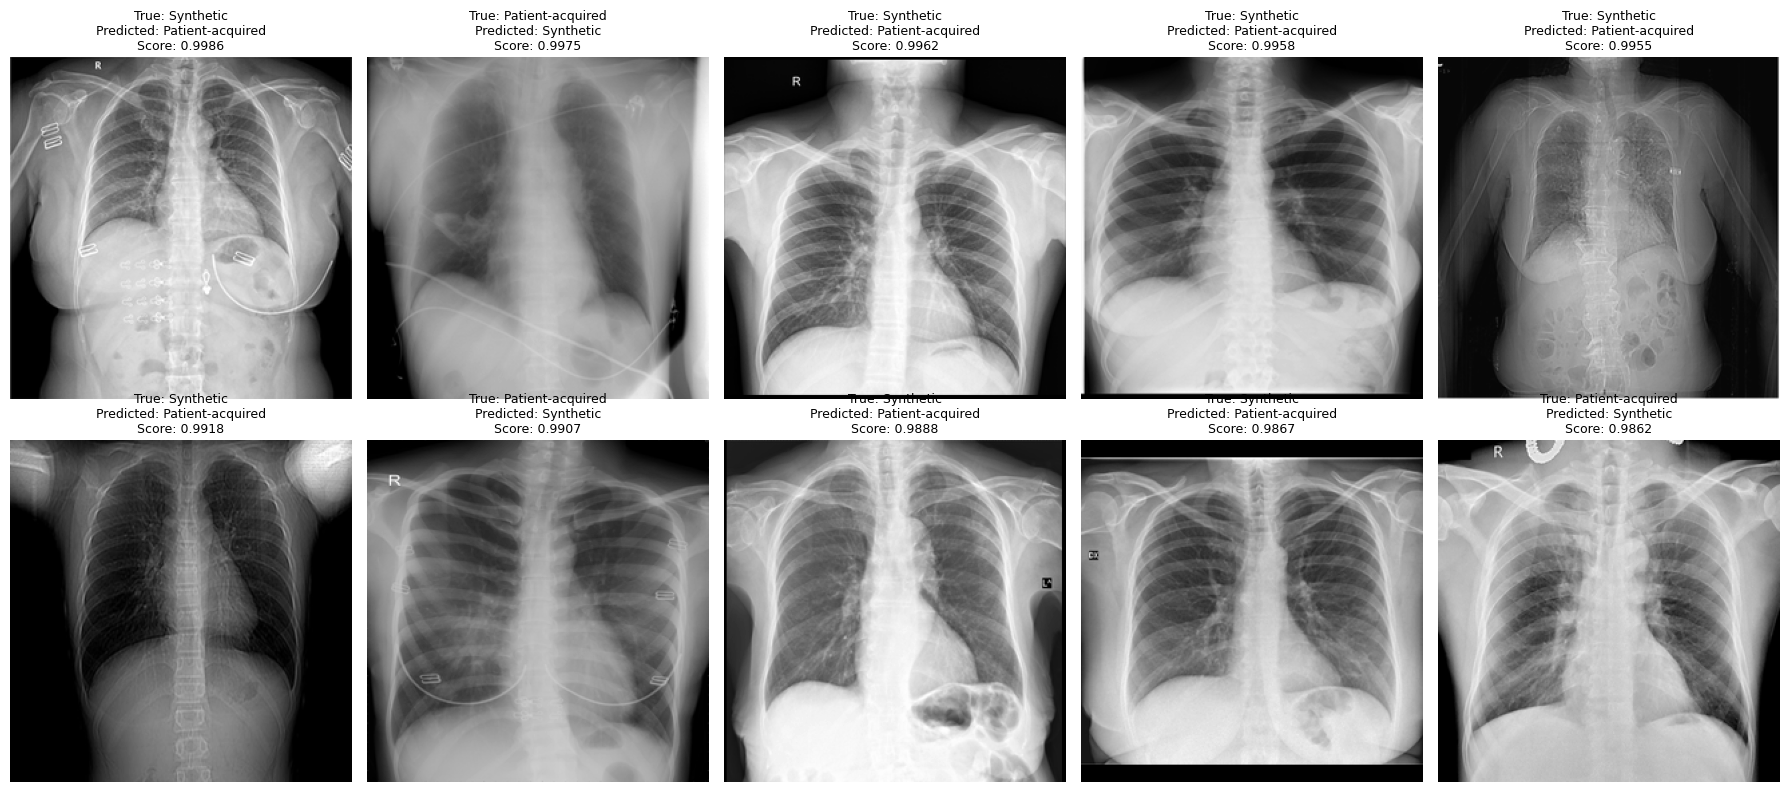

In [37]:
import matplotlib.pyplot as plt
from PIL import Image

errors = pd.DataFrame({
    "path": [str(p) for p in X_pool],
    "true_label": y_pool,
    "predicted_label": oof_predictions,
    "model_score": oof_scores})

errors = errors[
    errors["true_label"] != errors["predicted_label"]
].sort_values("model_score", ascending=False)

examples = errors.head(10).copy()
examples["withheld"] = examples["model_score"] < THRESHOLD

print("Incorrect binary predictions:", len(errors))
print("Incorrect predictions retained at threshold:",
      int((errors["model_score"] >= THRESHOLD).sum()))
print("Examples displayed:", len(examples))

display(examples)

names = {0: "Patient-acquired", 1: "Synthetic"}

if len(examples):
    fig, axes = plt.subplots(2, 5, figsize=(18, 8))

    for ax in axes.flat:
        ax.axis("off")

    for ax, (_, row) in zip(axes.flat, examples.iterrows()):
        with Image.open(row["path"]) as img:
            ax.imshow(img.convert("L"), cmap="gray")

        ax.set_title(
            f"True: {names[int(row['true_label'])]}\n"
            f"Predicted: {names[int(row['predicted_label'])]}\n"
            f"Score: {row['model_score']:.4f}",
            fontsize=9)

    plt.tight_layout()
    plt.show()

Some images contain borders, markers, or line-like objects. These could be investigated as possible source-related cues, but visual inspection alone cannot establish what caused the predictions.

**CHANGE**: I have changed the decision threshold from 0.50 to 0.80. It helped reduce errors among classified images, withholding 101 of the original 175 incorrect predictions.

**TEST RESULTS**

Loading the test set

In [38]:
run_dir = Path(
    "/home/vsarasani/Ray-Verify-/runs/"
    "resnet18_10epochs_20261020_161102_817014")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
THRESHOLD = 0.80

# Use the saved test split—do not create a new split.
test_manifest = pd.read_csv(run_dir / "test_manifest.csv")
test_labels = test_manifest["label"].to_numpy(dtype=np.int64)

test_dataset = XrayDataset(
    test_manifest["path"],
    test_labels,
    transform=eval_transform)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0)

# Check that all five saved models exist before starting.
for fold in range(1, 6):
    checkpoint = run_dir / f"fold_{fold}_model_10epochs.pth"
    if not checkpoint.is_file():
        raise FileNotFoundError(checkpoint)

print("Device:", device)
print("Test images:", len(test_dataset))
print("Patient-acquired:", int((test_labels == 0).sum()))
print("Synthetic:", int((test_labels == 1).sum()))
print("Threshold:", THRESHOLD)

Device: cuda
Test images: 2521
Patient-acquired: 1264
Synthetic: 1257
Threshold: 0.8


Averaging probabilities of all 5 folds. 

We average the two class probabilities—not the model weights or individual accuracy scores.

In [39]:
probability_sum = np.zeros(
    (len(test_dataset), 2),
    dtype=np.float64)

for fold in range(1, 6):
    # Recreate the architecture and load trained weights.
    model = resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, 2)

    checkpoint = run_dir / f"fold_{fold}_model_10epochs.pth"

    model.load_state_dict(
        torch.load(
            checkpoint,
            map_location="cpu",
            weights_only=True ) )

    model = model.to(device)
    model.eval()

    offset = 0

    with torch.no_grad():
        for images, _ in test_loader:
            outputs = model(images.to(device))
            probabilities = torch.softmax(
                outputs, dim=1
            ).cpu().numpy()

            assert np.isfinite(probabilities).all()

            end = offset + len(images)
            probability_sum[offset:end] += probabilities
            offset = end

    assert offset == len(test_dataset)
    print(f"Completed model {fold}/5")

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Average the class probabilities across five models.
test_probabilities = probability_sum / 5

# Binary prediction and its maximum average score.
test_predictions = test_probabilities.argmax(axis=1)
test_scores = test_probabilities.max(axis=1)

# -1 means Uncertain.
test_final = np.where(
    test_scores < THRESHOLD,
    -1,
    test_predictions)

print("Ensemble predictions completed.")

Completed model 1/5
Completed model 2/5
Completed model 3/5
Completed model 4/5
Completed model 5/5
Ensemble predictions completed.


Predictions and evaluation on test set

In [40]:
class_names = ["Patient-acquired", "Synthetic"]
names = {-1: "Uncertain", 0: "Patient-acquired", 1: "Synthetic"}

# Binary results: every image receives one of the two labels.
binary_report = classification_report(
    test_labels,
    test_predictions,
    labels=[0, 1],
    target_names=class_names,
    output_dict=True,
    zero_division=0)

print("TEST RESULTS BEFORE WITHHOLDING")
print(f"Accuracy: {accuracy_score(test_labels, test_predictions):.2%}")

print(classification_report(
    test_labels,
    test_predictions,
    labels=[0, 1],
    target_names=class_names,
    digits=4,
    zero_division=0))

# Thresholded results: Uncertain counts as a missed classification.
threshold_report = classification_report(
    test_labels,
    test_final,
    labels=[0, 1],
    target_names=class_names,
    output_dict=True,
    zero_division=0)

print("TEST RESULTS WITH THRESHOLD 0.80")

print(classification_report(
    test_labels,
    test_final,
    labels=[0, 1],
    target_names=class_names,
    digits=4,
    zero_division=0))

classified = test_final != -1
coverage = float(classified.mean())
uncertain_count = int((~classified).sum())

retained_error = (
    float((test_final[classified] != test_labels[classified]).mean())
    if classified.any() else None)

print("Total test images:", len(test_labels))
print("Classified images:", int(classified.sum()))
print("Uncertain images:", uncertain_count)
print(f"Coverage: {coverage:.2%}")

if retained_error is not None:
    print(f"Error among classified images: {retained_error:.2%}")
else:
    print("Error among classified images: undefined—none classified")

# Confusion table includes the Uncertain outputs.
confusion_table = pd.crosstab(
    pd.Series([names[int(y)] for y in test_labels], name="Actual"),
    pd.Series([names[int(p)] for p in test_final], name="Predicted")
).reindex(
    index=class_names,
    columns=class_names + ["Uncertain"],
    fill_value=0)

display(confusion_table)

# Save each image's scores and predictions.
test_results = pd.DataFrame({
    "path": test_manifest["path"],
    "true_label": test_labels,
    "patient_acquired_score": test_probabilities[:, 0],
    "synthetic_score": test_probabilities[:, 1],
    "binary_prediction": test_predictions,
    "model_score": test_scores,
    "final_prediction": [names[int(p)] for p in test_final]})

test_results.to_csv(
    run_dir / "ensemble_test_predictions.csv",
    index=False)

confusion_table.to_csv(
    run_dir / "ensemble_test_confusion_table.csv")

# Save the configuration and evaluation metrics.
metrics = {
    "model": "Five ResNet-18 models; equal average of softmax probabilities",
    "checkpoints": [
        f"fold_{fold}_model_10epochs.pth" for fold in range(1, 6)
    ],
    "threshold": THRESHOLD,
    "score_type": "Uncalibrated maximum average softmax score",
    "test_images": len(test_labels),
    "binary_accuracy": float(
        accuracy_score(test_labels, test_predictions)
    ),
    "binary_metrics": binary_report,
    "thresholded_metrics": threshold_report,
    "coverage": coverage,
    "uncertain_images": uncertain_count,
    "error_among_classified": retained_error}

(run_dir / "ensemble_test_metrics.json").write_text(
    json.dumps(metrics, indent=2))

print("Results saved in:", run_dir)

TEST RESULTS BEFORE WITHHOLDING
Accuracy: 98.06%
                  precision    recall  f1-score   support

Patient-acquired     0.9818    0.9794    0.9806      1264
       Synthetic     0.9794    0.9817    0.9805      1257

        accuracy                         0.9806      2521
       macro avg     0.9806    0.9806    0.9806      2521
    weighted avg     0.9806    0.9806    0.9806      2521

TEST RESULTS WITH THRESHOLD 0.80
                  precision    recall  f1-score   support

Patient-acquired     0.9942    0.9415    0.9671      1264
       Synthetic     0.9901    0.9578    0.9737      1257

       micro avg     0.9921    0.9496    0.9704      2521
       macro avg     0.9921    0.9496    0.9704      2521
    weighted avg     0.9921    0.9496    0.9704      2521

Total test images: 2521
Classified images: 2413
Uncertain images: 108
Coverage: 95.72%
Error among classified images: 0.79%


Predicted,Patient-acquired,Synthetic,Uncertain
Actual,,,
Patient-acquired,1190,12,62
Synthetic,7,1204,46


Results saved in: /home/vsarasani/Ray-Verify-/runs/resnet18_10epochs_20261020_161102_817014


Comparing training and test results 

In [41]:
import numpy as np
import pandas as pd

# Development predictions with the same threshold used for testing.
development_final = np.where(oof_scores < 0.80, -1, oof_predictions)

def summarize_results(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)
    rows = []

    for label, name in [(1, "Synthetic"), (0, "Patient-acquired")]:
        correct = int(((actual == label) & (predicted == label)).sum())
        predicted_count = int((predicted == label).sum())
        actual_count = int((actual == label).sum())

        precision = correct / predicted_count if predicted_count else 0
        recall = correct / actual_count if actual_count else 0
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0)

        rows.append({
            "Class": name,
            "Precision": f"{precision:.2%}",
            "Recall": f"{recall:.2%}",
            "F1": f"{f1:.2%}",
            "Predicted images": predicted_count,
            "Share of images": f"{predicted_count / len(actual):.2%}"})

    uncertain_count = int((predicted == -1).sum())

    rows.append({
        "Class": "Uncertain",
        "Precision": "N/A",
        "Recall": "N/A",
        "F1": "N/A",
        "Predicted images": uncertain_count,
        "Share of images": f"{uncertain_count / len(actual):.2%}"})

    return pd.DataFrame(rows).set_index("Class")

comparison = pd.concat({
    "Development validation": summarize_results(y_pool, development_final),
    "Test": summarize_results(test_labels, test_final)
}, axis=1)

display(comparison)

comparison.to_csv(run_dir / "development_vs_test_results.csv")

Development validation                                   \
                              Precision  Recall      F1 Predicted images   
Class                                                                      
Synthetic                        99.49%  96.32%  97.88%             4870   
Patient-acquired                 98.99%  95.27%  97.10%             4864   
Uncertain                           N/A     N/A     N/A              350   

                                      Test                                   \
                 Share of images Precision  Recall      F1 Predicted images   
Class                                                                         
Synthetic                 48.29%    99.01%  95.78%  97.37%             1216   
Patient-acquired          48.23%    99.42%  94.15%  96.71%             1197   
Uncertain                  3.47%       N/A     N/A     N/A              108   

                                  
                 Share of images  
Class                             
Synthetic                 48.23%  
Patient-acquired          47.48%  
Uncertain                  4.28%

Uncertain has no precision, recall, or F1 because it is a withheld decision, not a true dataset label. The development results use each image’s held-out fold model; the test results use the five-model average.

**Human Computer Interface** for resnet

I want to use gradio for HCI 

In [42]:
%pip install "gradio>=5,<6"

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Loading all five models

In [43]:
import gradio as gr

run_dir = Path(
    "/home/vsarasani/Ray-Verify-/runs/"
    "resnet18_10epochs_20261020_161102_817014")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
THRESHOLD = 0.80

ui_models = []

for fold in range(1, 6):
    model = resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, 2)

    model.load_state_dict(
        torch.load(
            run_dir / f"fold_{fold}_model_10epochs.pth",
            map_location="cpu",
            weights_only=True))

    model.to(device)
    model.eval()
    ui_models.append(model)

print("All five models loaded.")

All five models loaded.


Define curator actions

In [44]:
def analyze_image(image):
    if image is None:
        return "Please upload an image.", "", None

    try:
        # Same model preprocessing used during evaluation.
        image_tensor = eval_transform(
            image.convert("L")).unsqueeze(0).to(device)

        with torch.no_grad():
            probabilities = torch.stack([
                torch.softmax(model(image_tensor), dim=1)
                for model in ui_models]).mean(dim=0)[0]

        patient_score, synthetic_score = probabilities.cpu().tolist()

        score = max(patient_score, synthetic_score)
        predicted = (
            "Patient-acquired"
            if patient_score >= synthetic_score
            else "Synthetic")

        if score < THRESHOLD:
            prediction = "Uncertain"
            explanation = (
                "Classification withheld. Review the image's source "
                "and provenance before making a decision.")
        else:
            prediction = predicted
            explanation = (
                "Check the source and provenance before making "
                "your final decision." )

        result = f"## {prediction}\n\n{explanation}"

        score_text = (
            f"Patient-acquired score: {patient_score:.4f}\n"
            f"Synthetic score: {synthetic_score:.4f}\n"
            f"Withholding threshold: {THRESHOLD:.2f}\n\n"
            "These are uncalibrated model scores, "
            "not probabilities of correctness." )

        record = {
            "prediction": prediction,
            "score": score }

        return result, score_text, record

    except Exception:
        return (
            "Unable to analyze this image. Try a readable PNG or JPEG.",
            "",
            None )


def record_decision(record, decision, notes):
    if record is None:
        return "Analyze an image before recording a decision."

    message = (
        f"AI prediction: {record['prediction']}\n"
        f"Curator decision: {decision}\n"
        f"Notes: {notes.strip() or 'None'}\n\n"
        "Recorded for this session only.")

    return message


def reset_result():
    return (
        "## Ready to analyze",
        "",
        None,
        "Leave unresolved",
        "",
        "")

Launching interface

In [45]:
css = """
.gradio-container {
    max-width: 1100px !important;
    margin: auto;
}
#header {
    background: linear-gradient(120deg, #12344d, #126c78);
    padding: 26px;
    border-radius: 16px;
    margin-bottom: 20px;
}
#header h1, #header p {
    color: white !important;
}
"""

with gr.Blocks(
    theme=gr.themes.Soft(),
    css=css,
    title="Ray Verify",
    delete_cache=(3600, 3600)
) as demo:

    gr.HTML("""
        <div id="header">
            <h1>Ray Verify</h1>
            <p>Chest X-ray origin screening for research data curation</p>
        </div>
    """)

    gr.Markdown(
        "Upload a de-identified chest X-ray, review the AI output, "
        "and record your own decision. "
        "**Research prototype — not a diagnostic tool.**")

    current_record = gr.State(None)

    with gr.Row():
        with gr.Column():
            image_input = gr.Image(
                label="Upload chest X-ray",
                type="pil",
                sources=["upload"],
                height=350 )

            with gr.Row():
                analyze_button = gr.Button(
                    "Analyze image",
                    variant="primary")
                clear_button = gr.Button("Clear")

        with gr.Column():
            result = gr.Markdown("## Ready to analyze")

            scores = gr.Textbox(
                label="Model scores",
                lines=6,
                interactive=False )

            gr.Markdown(
                "**How to interpret the result:** "
                "A maximum average score below 0.80 produces "
                "Uncertain. A high score can still be incorrect.")

    gr.Markdown("### Curator review")
    gr.Markdown(
        "Your decision is separate from the AI prediction. "
        "You may disagree with the model or leave the image unresolved."  )

    decision = gr.Radio(
        choices=[
            "Include in research dataset",
            "Exclude from research dataset",
            "Leave unresolved"],
        value="Leave unresolved",
        label="Your decision" )

    notes = gr.Textbox(
        label="Review notes",
        placeholder="Explain your decision or what needs further checking.",
        lines=3)

    record_button = gr.Button("Record session decision")

    decision_summary = gr.Textbox(
        label="Curator decision record",
        lines=5,
        interactive=False)

    gr.Markdown(
        "Decisions are kept only in this session. "
        "Only upload de-identified research images. "
        "The system does not verify that an uploaded image is a chest X-ray." )

    # Changing the image clears the previous prediction and decision.
    image_input.change(
        fn=reset_result,
        inputs=[],
        outputs=[
            result, scores, current_record,
            decision, notes, decision_summary ],
        queue=False)

    analyze_button.click(
        fn=analyze_image,
        inputs=image_input,
        outputs=[result, scores, current_record],
        concurrency_limit=1 )

    record_button.click(
        fn=record_decision,
        inputs=[current_record, decision, notes],
        outputs=decision_summary )

    clear_button.click(
        fn=lambda: None,
        inputs=[],
        outputs=image_input )

demo.queue().launch(
    inline=True,
    share=True,
    max_file_size="10mb")

/tmp/ipykernel_1882259/1864600532.py:17: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(
/tmp/ipykernel_1882259/1864600532.py:17: DeprecationWarning: The 'css' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'css' to Blocks.launch() instead.
  with gr.Blocks(


* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://3c18f792fa79d0055d.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


This is the end to end human-computer interface. 

**Densenet model is being implemented for Experimental setup**

In [46]:
from torchvision.models import densenet121, DenseNet121_Weights
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score)
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn

# Preserve your existing ResNet development predictions.
resnet_predictions = np.asarray(oof_predictions).copy()
resnet_scores = np.asarray(oof_scores).copy()

DN_EPOCHS = 10
DN_BATCH_SIZE = 16
DN_LR = 0.001
DN_SEED = 42

# A separate directory for DenseNet results.
dn_run_dir = Path(
    "/home/vsarasani/Ray-Verify-/runs/"
    f"densenet121_10epochs_{datetime.now():%Y%m%d_%H%M%S_%f}")
dn_run_dir.mkdir(parents=True, exist_ok=False)

def build_densenet():
    model = densenet121(
        weights=DenseNet121_Weights.IMAGENET1K_V1)

    for parameter in model.parameters():
        parameter.requires_grad = False

    model.classifier = nn.Linear(
        model.classifier.in_features, 2)

    return model.to(device)

dn_predictions = np.full(len(y_pool), -1, dtype=int)
dn_scores = np.full(len(y_pool), np.nan)
dn_history = []

print("DenseNet results will be saved in:", dn_run_dir)

DenseNet results will be saved in: /home/vsarasani/Ray-Verify-/runs/densenet121_10epochs_20261026_140631_831104


In [47]:
for fold_number, (train_idx, val_idx) in enumerate(folds, start=1):
    print(f"\nStarting DenseNet fold {fold_number}/5", flush=True)

    set_seed(DN_SEED + fold_number)

    dn_model = build_densenet()

    train_loader, val_loader = make_fold_loaders(
        train_idx, val_idx, batch_size=DN_BATCH_SIZE)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        dn_model.classifier.parameters(),
        lr=DN_LR)

    for epoch in range(1, DN_EPOCHS + 1):
        # Keep the frozen feature extractor in evaluation mode.
        dn_model.eval()
        dn_model.classifier.train()

        train_loss = 0.0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = dn_model(images)
            loss = criterion(outputs, labels)

            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite training loss.")

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * len(labels)

        train_loss /= len(train_loader.dataset)

        # Evaluate only this fold's validation images.
        dn_model.eval()
        actual, predicted, scores = [], [], []
        val_loss = 0.0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = dn_model(images)
                loss = criterion(outputs, labels)

                probabilities = torch.softmax(outputs, dim=1)
                batch_scores, batch_predictions = probabilities.max(dim=1)

                val_loss += loss.item() * len(labels)
                actual.extend(labels.cpu().tolist())
                predicted.extend(batch_predictions.cpu().tolist())
                scores.extend(batch_scores.cpu().tolist())

        val_loss /= len(val_loader.dataset)

        accuracy = accuracy_score(actual, predicted)
        precision = precision_score(actual, predicted, zero_division=0)
        recall = recall_score(actual, predicted, zero_division=0)
        f1 = f1_score(actual, predicted, zero_division=0)

        dn_history.append({
            "fold": fold_number,
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "accuracy": accuracy,
            "precision": precision,
            "recall": recall,
            "f1": f1 })

        print(
            f"Fold {fold_number}/5 | Epoch {epoch}/{DN_EPOCHS} | "
            f"Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f} | "
            f"Accuracy: {accuracy:.4f} | Precision: {precision:.4f} | "
            f"Recall: {recall:.4f} | F1: {f1:.4f}",
            flush=True)

    # Save epoch-10 predictions for the held-out fold.
    dn_predictions[val_idx] = predicted
    dn_scores[val_idx] = scores

    torch.save(
        {
            key: value.detach().cpu()
            for key, value in dn_model.state_dict().items()
        },
        dn_run_dir / f"fold_{fold_number}_model_10epochs.pth")

    pd.DataFrame(dn_history).to_csv(
        dn_run_dir / "training_history.csv",
        index=False)

    del dn_model, optimizer

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

assert (dn_predictions >= 0).all()
assert np.isfinite(dn_scores).all()

pd.DataFrame({
    "path": [str(path) for path in X_pool],
    "true_label": y_pool,
    "predicted_label": dn_predictions,
    "model_score": dn_scores
}).to_csv(
    dn_run_dir / "development_predictions.csv",
    index=False)

print("\nDenseNet training completed.")


Starting DenseNet fold 1/5
Fold 1/5 | Epoch 1/10 | Train loss: 0.1370 | Val loss: 0.1022 | Accuracy: 0.9608 | Precision: 0.9905 | Recall: 0.9304 | F1: 0.9595
Fold 1/5 | Epoch 2/10 | Train loss: 0.0718 | Val loss: 0.0810 | Accuracy: 0.9747 | Precision: 0.9659 | Recall: 0.9841 | F1: 0.9749
Fold 1/5 | Epoch 3/10 | Train loss: 0.0597 | Val loss: 0.0741 | Accuracy: 0.9717 | Precision: 0.9927 | Recall: 0.9503 | F1: 0.9711
Fold 1/5 | Epoch 4/10 | Train loss: 0.0550 | Val loss: 0.0643 | Accuracy: 0.9762 | Precision: 0.9928 | Recall: 0.9592 | F1: 0.9757
Fold 1/5 | Epoch 5/10 | Train loss: 0.0478 | Val loss: 0.0558 | Accuracy: 0.9836 | Precision: 0.9803 | Recall: 0.9871 | F1: 0.9837
Fold 1/5 | Epoch 6/10 | Train loss: 0.0445 | Val loss: 0.0501 | Accuracy: 0.9856 | Precision: 0.9890 | Recall: 0.9821 | F1: 0.9855
Fold 1/5 | Epoch 7/10 | Train loss: 0.0411 | Val loss: 0.0496 | Accuracy: 0.9846 | Precision: 0.9919 | Recall: 0.9771 | F1: 0.9845
Fold 1/5 | Epoch 8/10 | Train loss: 0.0385 | Val loss: 

Compare both models using the same 0.80 threshold

In [48]:
def comparison_metrics(predictions, scores):
    actual = np.asarray(y_pool)

    final = np.where(scores < 0.80, -1, predictions)
    classified = final != -1

    true_positive = ((actual == 1) & (final == 1)).sum()
    predicted_synthetic = (final == 1).sum()
    actual_synthetic = (actual == 1).sum()

    precision = (
        true_positive / predicted_synthetic
        if predicted_synthetic else 0.0)
    recall = true_positive / actual_synthetic
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0)

    return {
        "Synthetic precision": precision,
        "Synthetic recall": recall,
        "Synthetic F1": f1,
        "Patient-acquired recall": (final[actual == 0] == 0).mean(),
        "Coverage": classified.mean(),
        "Error among classified": (
            (final[classified] != actual[classified]).mean()
            if classified.any() else np.nan),
        "Uncertain images": int((~classified).sum()) }

comparison = pd.DataFrame({"ResNet-18": comparison_metrics(resnet_predictions, resnet_scores),
    "DenseNet-121": comparison_metrics(dn_predictions, dn_scores)}).T

display(comparison.style.format({
        column: "{:.2%}"
        for column in comparison.columns
        if column != "Uncertain images" }).format({"Uncertain images": "{:.0f}"}))

comparison.to_csv(dn_run_dir / "resnet_vs_densenet_development.csv")

,Synthetic precision,Synthetic recall,Synthetic F1,Patient-acquired recall,Coverage,Error among classified,Uncertain images
ResNet-18,0.994867,0.963221,0.978788,0.952711,0.965292,0.007602,350
DenseNet-121,0.996090,0.962227,0.978865,0.971508,0.973225,0.006521,270


Comparing results on Validation data 

Densenet on Test set 

In [49]:
from torch.utils.data import DataLoader
from torchvision.models import densenet121
from sklearn.metrics import precision_recall_fscore_support

resnet_run_dir = run_dir

# Read the saved ResNet test predictions.
resnet_test = pd.read_csv(
    resnet_run_dir / "ensemble_test_predictions.csv")

# Preserve exactly the same image order and labels.
comparison_labels = resnet_test["true_label"].to_numpy(dtype=np.int64)

dn_test_dataset = XrayDataset(
    resnet_test["path"],
    comparison_labels,
    transform=eval_transform)

dn_test_loader = DataLoader(
    dn_test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0)

TEST_THRESHOLD = 0.80

for fold in range(1, 6):
    checkpoint = dn_run_dir / f"fold_{fold}_model_10epochs.pth"
    if not checkpoint.is_file():
        raise FileNotFoundError(checkpoint)

print("ResNet folder:", resnet_run_dir)
print("DenseNet folder:", dn_run_dir)
print("Test images:", len(dn_test_dataset))

ResNet folder: /home/vsarasani/Ray-Verify-/runs/resnet18_10epochs_20261020_161102_817014
DenseNet folder: /home/vsarasani/Ray-Verify-/runs/densenet121_10epochs_20261026_140631_831104
Test images: 2521


Averaging all 5 models

In [50]:
dn_probability_sum = np.zeros(
    (len(dn_test_dataset), 2),
    dtype=np.float64)

for fold in range(1, 6):
    model = densenet121(weights=None)
    model.classifier = nn.Linear(model.classifier.in_features, 2)

    model.load_state_dict(
        torch.load(
            dn_run_dir / f"fold_{fold}_model_10epochs.pth",
            map_location="cpu",
            weights_only=True) )

    model = model.to(device)
    model.eval()
    offset = 0

    with torch.no_grad():
        for images, _ in dn_test_loader:
            outputs = model(images.to(device))
            probabilities = torch.softmax(
                outputs, dim=1
            ).cpu().numpy()

            assert np.isfinite(probabilities).all()

            end = offset + len(images)
            dn_probability_sum[offset:end] += probabilities
            offset = end

    assert offset == len(dn_test_dataset)
    print(f"Completed DenseNet model {fold}/5")

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

dn_test_probabilities = dn_probability_sum / 5
dn_test_predictions = dn_test_probabilities.argmax(axis=1)
dn_test_scores = dn_test_probabilities.max(axis=1)

dn_test_final = np.where(
    dn_test_scores < TEST_THRESHOLD,
    -1,
    dn_test_predictions)

print("DenseNet test predictions completed.")

Completed DenseNet model 1/5
Completed DenseNet model 2/5
Completed DenseNet model 3/5
Completed DenseNet model 4/5
Completed DenseNet model 5/5
DenseNet test predictions completed.


Results

In [51]:
# Apply the same threshold to the saved ResNet scores.
resnet_test_final = np.where(
    resnet_test["model_score"].to_numpy() < TEST_THRESHOLD,
    -1,
    resnet_test["binary_prediction"].to_numpy(dtype=int))

def test_metrics(actual, final):
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual,
        final,
        labels=[0, 1],
        zero_division=0)

    classified = final != -1

    return {
        "Synthetic precision": precision[1],
        "Synthetic recall": recall[1],
        "Synthetic F1": f1[1],
        "Patient-acquired precision": precision[0],
        "Patient-acquired recall": recall[0],
        "Patient-acquired F1": f1[0],
        "Coverage": classified.mean(),
        "Error among classified": (
            (final[classified] != actual[classified]).mean()
            if classified.any() else np.nan
        ),
        "Uncertain images": int((~classified).sum()) }

test_comparison = pd.DataFrame({
    "ResNet-18 ensemble": test_metrics(
        comparison_labels, resnet_test_final),
    "DenseNet-121 ensemble": test_metrics(
        comparison_labels, dn_test_final)}).T

display(
    test_comparison.style.format({
        column: "{:.2%}"
        for column in test_comparison.columns
        if column != "Uncertain images" }).format({"Uncertain images": "{:.0f}"}))

# Save DenseNet predictions.
names = {-1: "Uncertain", 0: "Patient-acquired", 1: "Synthetic"}

pd.DataFrame({
    "path": resnet_test["path"],
    "true_label": comparison_labels,
    "patient_acquired_score": dn_test_probabilities[:, 0],
    "synthetic_score": dn_test_probabilities[:, 1],
    "binary_prediction": dn_test_predictions,
    "model_score": dn_test_scores,
    "final_prediction": [names[int(p)] for p in dn_test_final]
}).to_csv(
    dn_run_dir / "ensemble_test_predictions.csv",
    index=False)

test_comparison.to_csv(
    dn_run_dir / "resnet_vs_densenet_test.csv")

(dn_run_dir / "test_evaluation_config.json").write_text(
    json.dumps({
        "threshold": TEST_THRESHOLD,
        "ensemble": "Equal average of five models' softmax probabilities",
        "test_images": len(comparison_labels),
        "resnet_results_source": str(
            resnet_run_dir / "ensemble_test_predictions.csv")}, indent=2))

print("Results saved in:", dn_run_dir)

,Synthetic precision,Synthetic recall,Synthetic F1,Patient-acquired precision,Patient-acquired recall,Patient-acquired F1,Coverage,Error among classified,Uncertain images
ResNet-18 ensemble,0.990132,0.957836,0.973716,0.994152,0.941456,0.967087,0.957160,0.007874,108
DenseNet-121 ensemble,0.995078,0.964996,0.979806,0.995173,0.978639,0.986837,0.976597,0.004874,59


Results saved in: /home/vsarasani/Ray-Verify-/runs/densenet121_10epochs_20261026_140631_831104


**Human Computer Interface** for densenet

Loading 5 densenet models

In [52]:
import gradio as gr
import torch

from torch import nn
from torchvision.models import densenet121

dn_ui_models = []

for fold in range(1, 6):
    model = densenet121(weights=None)
    model.classifier = nn.Linear(model.classifier.in_features, 2)

    model.load_state_dict(
        torch.load(
            dn_run_dir / f"fold_{fold}_model_10epochs.pth",
            map_location="cpu",
            weights_only=True ))

    model.to(device)
    model.eval()
    dn_ui_models.append(model)

print("Five DenseNet models loaded.")

Five DenseNet models loaded.


Defining action OF Densenet

In [53]:
def analyze_densenet(image):
    if image is None:
        return "Please upload an image first.", "", None, ""

    try:
        tensor = eval_transform(
            image.convert("L")).unsqueeze(0).to(device)

        with torch.no_grad():
            probabilities = torch.stack([
                torch.softmax(model(tensor), dim=1)
                for model in dn_ui_models ]).mean(dim=0)[0]

        patient_score, synthetic_score = probabilities.cpu().tolist()
        maximum_score = max(patient_score, synthetic_score)

        if maximum_score < 0.80:
            prediction = "Uncertain"
            guidance = (
                "Classification withheld. Check the image's source "
                "and provenance before deciding." )
        else:
            prediction = (
                "Patient-acquired"
                if patient_score >= synthetic_score
                else "Synthetic")
            guidance = (
                "Review the image's source and provenance. "
                "The model can still be incorrect." )

        scores = (
            f"Patient-acquired: {patient_score:.4f}\n"
            f"Synthetic: {synthetic_score:.4f}\n"
            f"Withholding threshold: 0.80\n\n"
            "Uncalibrated model scores—not probabilities of correctness.")

        return (
            f"## {prediction}\n\n{guidance}",
            scores,
            {"prediction": prediction},
            "")

    except Exception as error:
        print("DenseNet inference error:", repr(error))
        return (
            "Analysis failed. Try another readable image.",
            "",
            None,
            "" )


def record_densenet_decision(record, decision, notes):
    if record is None:
        return "Analyze an image before recording your decision."

    return (f"AI prediction: {record['prediction']}\n"
        f"Curator decision: {decision}\n"
        f"Notes: {notes.strip() or 'None'}\n\n"
        "This record is displayed for this session only.")


def reset_densenet():
    return (
        "## Ready to analyze",
        "",
        None,
        "Leave unresolved",
        "",
        "")

Launching interface

In [54]:
dn_css = """
.gradio-container {
    max-width: 1100px !important;
    margin: auto;
}
#dn-header {
    background: linear-gradient(120deg, #17324d, #087f8c);
    padding: 26px;
    border-radius: 16px;
    margin-bottom: 18px;
}
#dn-header h1, #dn-header p {
    color: white !important;
}
"""

# Close an earlier DenseNet interface if this cell is rerun.
if "dn_demo" in globals():
    dn_demo.close()

with gr.Blocks(
    title="Ray Verify | DenseNet",
    theme=gr.themes.Soft(),
    css=dn_css,
    delete_cache=(3600, 3600)
) as dn_demo:

    gr.HTML("""
        <div id="dn-header">
            <h1>Ray Verify</h1>
            <p>Chest X-ray origin screening · DenseNet-121 ensemble</p>
        </div>
    """)

    gr.Markdown(
        "Upload a de-identified chest X-ray, review the prediction, "
        "and make your own decision. "
        "**Research prototype—not for medical diagnosis.**")

    dn_record = gr.State(None)

    with gr.Row():
        with gr.Column():
            dn_image = gr.Image(
                label="Upload chest X-ray",
                type="pil",
                sources=["upload"],
                height=350)

            with gr.Row():
                dn_analyze = gr.Button(
                    "Analyze image",
                    variant="primary" )
                dn_clear = gr.Button("Clear")

        with gr.Column():
            dn_result = gr.Markdown("## Ready to analyze")

            dn_scores_display = gr.Textbox(
                label="Average scores from five models",
                lines=6,
                interactive=False)

            gr.Markdown(
                "**Uncertain** means the highest average score "
                "is below 0.80. A higher score does not guarantee "
                "a correct prediction." )

    gr.Markdown("### Your review")
    gr.Markdown(
        "Your decision remains separate from the AI prediction. "
        "You can disagree with the model or leave the case unresolved.")

    dn_decision = gr.Radio(
        choices=[
            "Include in research dataset",
            "Exclude from research dataset",
            "Leave unresolved" ],
        value="Leave unresolved",
        label="Curator decision")

    dn_notes = gr.Textbox(
        label="Review notes",
        placeholder="Explain your decision or what needs checking.",
        lines=3)

    dn_save = gr.Button("Record session decision")

    dn_summary = gr.Textbox(
        label="Decision record",
        lines=5,
        interactive=False)

    gr.Markdown("Decisions are displayed for this session only and are not "
        "saved to a database. Upload only de-identified research images. "
        "This prototype does not check whether an image is a chest X-ray.")

    dn_image.change(
        fn=reset_densenet,
        inputs=[],
        outputs=[
            dn_result, dn_scores_display, dn_record,
            dn_decision, dn_notes, dn_summary ])

    dn_analyze.click(
        fn=analyze_densenet,
        inputs=dn_image,
        outputs=[
            dn_result, dn_scores_display, dn_record, dn_summary ],
        concurrency_limit=1)

    dn_save.click(
        fn=record_densenet_decision,
        inputs=[dn_record, dn_decision, dn_notes],
        outputs=dn_summary)

    dn_clear.click(
        fn=lambda: None,
        inputs=[],
        outputs=dn_image)

dn_demo.queue().launch(
    inline=True,
    share=True,
    max_file_size="10mb")

/tmp/ipykernel_1882259/4112755906.py:21: DeprecationWarning: The 'theme' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'theme' to Blocks.launch() instead.
  with gr.Blocks(
/tmp/ipykernel_1882259/4112755906.py:21: DeprecationWarning: The 'css' parameter in the Blocks constructor will be removed in Gradio 6.0. You will need to pass 'css' to Blocks.launch() instead.
  with gr.Blocks(


* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://79581c630521810f93.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


I am selecting Densenet ensemble for my project because DenseNet-121 outperformed ResNet-18 on all nine reported comparison measures at the same 0.80 threshold.

It provides better classification and coverage metrics and reduces the number of uncertain cases